# Meet AlexNet: loading a network and classifying one image
**Background:** Krizhevsky, A., Sutskever, I., & Hinton, G. E. (2012). ImageNet classification with deep convolutional neural networks. *NeurIPS, 25*.

AlexNet was trained on **ImageNet**: about 1.2 million photos, each labelled with one of **1,000 categories**.

**What you will do**
1. Load AlexNet with its trained weights
2. Print its architecture and look at its layers
3. Prepare one image for the network
4. Classify the image and look at the top-5 predictions

## Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
import torch
from torchvision import models, transforms
device = "cpu"

In [2]:
# Find the course data: on JupyterHub it is in Sciebo, on your own computer
# it is in the "images" folder next to this notebook
sciebo = sorted(Path.home().glob("sciebo/*/Week2/"))     # works even if the shared folder was renamed
if sciebo:
    DATA = sciebo[0]                                     # JupyterHub (Sciebo)
    IMAGE_FILE = DATA / "example.JPEG"
else:
    DATA = Path.cwd()                                    # your computer: the folder of this notebook
    IMAGE_FILE = next((DATA / "images").glob("example.*"), DATA / "images" / "example.JPEG")

if not IMAGE_FILE.exists():
    raise FileNotFoundError(
        f"The image example.JPEG (or .jpg) was not found in {IMAGE_FILE.parent}.\n"
        "On JupyterHub: did you connect Sciebo when starting the server, and accept the shared CNU folder?\n"
        "On your own computer: put example.JPEG (or example.jpg) in the \"images\" folder next to this notebook."
    )
print(f"Using data from {DATA}")

Using data from /Users/ekindogailkel/Cognitive_Neuroscience_Update/Week2-Intro-AlexNet


## 1. Load AlexNet
The **architecture** is the structure of the network: which layers there are and how they are connected. The **weights** are the numbers the network learned during training. Without trained weights, AlexNet would just guess randomly.

In [5]:
# Load AlexNet with its trained weights.
weights = models.AlexNet_Weights.IMAGENET1K_V1   # the ImageNet-trained version
model = models.alexnet(weights=weights)

# .eval() switches off training-only behaviour, so predictions are stable
model = model.to(device).eval()

# The names of the 1,000 categories, in the order of the network's outputs
categories = weights.meta["categories"]
print(f"AlexNet knows {len(categories)} categories")
print(categories)

AlexNet knows 1000 categories
['tench', 'goldfish', 'great white shark', 'tiger shark', 'hammerhead', 'electric ray', 'stingray', 'cock', 'hen', 'ostrich', 'brambling', 'goldfinch', 'house finch', 'junco', 'indigo bunting', 'robin', 'bulbul', 'jay', 'magpie', 'chickadee', 'water ouzel', 'kite', 'bald eagle', 'vulture', 'great grey owl', 'European fire salamander', 'common newt', 'eft', 'spotted salamander', 'axolotl', 'bullfrog', 'tree frog', 'tailed frog', 'loggerhead', 'leatherback turtle', 'mud turtle', 'terrapin', 'box turtle', 'banded gecko', 'common iguana', 'American chameleon', 'whiptail', 'agama', 'frilled lizard', 'alligator lizard', 'Gila monster', 'green lizard', 'African chameleon', 'Komodo dragon', 'African crocodile', 'American alligator', 'triceratops', 'thunder snake', 'ringneck snake', 'hognose snake', 'green snake', 'king snake', 'garter snake', 'water snake', 'vine snake', 'night snake', 'boa constrictor', 'rock python', 'Indian cobra', 'green mamba', 'sea snake', '

## 2. The architecture
Please compare this output with the diagram from the first week. Is it a match?

In [5]:
print(model)

AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

AlexNet has two parts:

- **`features`**: 5 **convolutional layers** (`Conv2d`). Each one slides small filters over the image and detects patterns: edges and colours in the first layer, more complex shapes and object parts in later layers. After each one comes a **`ReLU`**, which sets negative values to zero, and sometimes a **`MaxPool2d`**, which shrinks the image by keeping the strongest response in each small region.
- **`classifier`**: 3 **fully connected layers** (`Linear`). These combine all the features into one decision. The last layer has **1,000 outputs**, one for each category. (`Dropout` is only used during training.)

In [6]:
# Look at a single layer: the first convolutional layer
first_layer = model.features[0]
print(first_layer)

Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))


`Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), ...)` means: the input has **3** channels (red, green, blue), the layer has **64** filters, each filter is **11 × 11** pixels, and it moves **4** pixels at a time.

## 3. Prepare one image
AlexNet always takes a 224 × 224 pixel image. Every image is **resized**, **cropped** to the centre, and its colours are **normalised** the same way as during training.

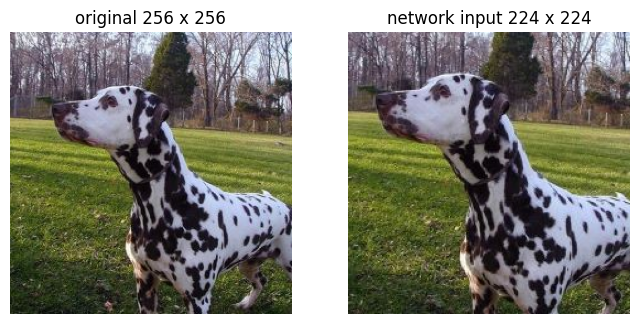

In [9]:
img = Image.open(IMAGE_FILE).convert("RGB")       # convert("RGB") ensures 3 colour channels

# The full preparation that goes into the network
preprocess = transforms.Compose([
    transforms.Resize(256),        # resize
    transforms.CenterCrop(224),    # cut out the central 224 x 224 square
    transforms.ToTensor(),         # turn the image into numbers (PyTorch's tensor format)
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # same colour normalisation
                         std=[0.229, 0.224, 0.225]),   # as in ImageNet training
])

# The same steps without the number conversion, so we can SHOW what the network sees
what_network_sees = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224)])

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img); axes[0].set_title(f"original {img.size[0]} x {img.size[1]}")
axes[1].imshow(what_network_sees(img)); axes[1].set_title("network input 224 x 224")
for ax in axes: ax.axis("off")
plt.show()

In [10]:
# The network expects a BATCH of images, so we add a batch dimension of size 1
x = preprocess(img).unsqueeze(0).to(device)
print(f"Input shape: {tuple(x.shape)}   (images, colour channels, height, width)")

Input shape: (1, 3, 224, 224)   (images, colour channels, height, width)


## 4. Classify the image

In [11]:
# We only predict, we don't train: no gradients needed
with torch.no_grad():
    outputs = model(x)

print(f"Output shape: {tuple(outputs.shape)}   (images, categories)")

# Softmax turns the 1,000 raw outputs into probabilities that sum to 1
probs = torch.softmax(outputs, dim=1)[0]
print(f"Sum of all probabilities: {probs.sum().item():.2f}")

Output shape: (1, 1000)   (images, categories)
Sum of all probabilities: 1.00


In [12]:
# The 5 most likely categories
top_probs, top_idx = probs.topk(5)
for p, i in zip(top_probs, top_idx):
    print(f"{categories[i]:30s} {p.item():.3f}")

dalmatian                      0.998
Great Dane                     0.002
English setter                 0.000
German short-haired pointer    0.000
Saluki                         0.000


### Congrats! You classified an image using a CNN!!!